# Visualization of the contraction from Ando and Blumenthal

Import

In [1]:
#%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import cumulative_trapezoid
from scipy.integrate import quad
from scipy.interpolate import interp1d
from scipy.optimize import root_scalar
from scipy.special import gamma, gammainc

from astropy.cosmology import Planck18 as cosmo
from astropy import units as u

import pandas as pd
import os

import constantes
import config
import contraction
import profiles
import general


/Users/baptistesevilla/Documents/Ecole/Stage Dark matter/Code/profiles.py:293: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  val, _ = quad(integrand, 0.0, np.inf, limit=constantes.ABEL_LIMIT, epsrel=epsrel, epsabs= constantes.ABEL_EPSABS)


Params for the plots

In [2]:
x_min = 1e-6
x_max = 1
y_min = 1e-8
y_max = 1e4

fig = 10

plt.rcParams['axes.labelsize'] = 20  
plt.rcParams['xtick.labelsize'] = 18   
plt.rcParams['ytick.labelsize'] = 18

Params defined from the article Shin’ichiro Ando and Daisuke Nagai (2012)

In [3]:
HALO_MASS = 1.714e14 
CONCENTRATION = 5.6

Choice of the the baryons, dark matter and method of contraction

In [4]:
config.BARYON_PROFILE = 'Nuker' 
config.CONTRACTION = 'Ando'
config.DM_PROFILE = 'Einasto'

# Virial radius
R_VIR = (HALO_MASS / ((4.0 / 3.0) * np.pi * constantes.DELTA_VIR * constantes.RHO_C))**(1.0 / 3.0)

M_B = constantes.F_B * HALO_MASS # Total baryonic mass


Creation of the halo

In [5]:
halo = profiles.Halo(
    halo_mass = HALO_MASS, 
    concentration = CONCENTRATION, 
    rho_c = constantes.RHO_C, 
    z = constantes.Z, 
    omega_m = constantes.OMEGA_M, 
    omega_l = constantes.OMEGA_L, 
    alpha = constantes.ALPHA_EINASTO)


r = config.R


# Dark matter profil
if config.DM_PROFILE == 'NFW':
    rho_dm = (1.0 - constantes.F_B) * halo.density_nfw(r)
    mass_dm = (1.0 - constantes.F_B) * halo.mass_nfw(r)
elif config.DM_PROFILE == 'Einasto':
    rho_dm = (1.0 - constantes.F_B) * halo.density_einasto(r)
    mass_dm = (1.0 - constantes.F_B) * halo.mass_einasto(r)
elif config.DM_PROFILE == 'Burkert':
    rho_dm = (1.0 - constantes.F_B) * halo.density_burkert(r)
    mass_dm = (1.0 - constantes.F_B) * halo.mass_burkert(r)
elif config.DM_PROFILE == 'Custom':
    rho_dm = (1.0 - constantes.F_B) * halo.density_custom(r)
    mass_dm = (1.0 - constantes.F_B) * halo.mass_custom(r)


# Baryons
if config.BARYON_PROFILE == 'Hernquist':
    rho_b = profiles.hernquist_density(r, constantes.M_B, constantes.R_B)
    mass_b = profiles.hernquist_mass(r, constantes.M_B, constantes.R_B)
elif config.BARYON_PROFILE == 'Disk':
    rho_b = profiles.disk_density(r, constantes.M_B, constantes.R_B)
    mass_b = profiles.disk_mass(r, constantes.M_B, constantes.R_B)
elif config.BARYON_PROFILE == 'Nuker':
    rho_b = profiles.nuker_density(r)
    mass_b = profiles.nuker_mass(r)

masse_gaz = [profiles.exact_gas_mass(ri) for ri in r]
mass_gas_interp = interp1d(r, masse_gaz, bounds_error=False, fill_value=(masse_gaz[0], masse_gaz[-1]))
rho_gaz = profiles.exact_gas_density(r)

Contraction

In [6]:
def contract(rho_dm, mb_stars_func, mb_gas_func=None, method=config.CONTRACTION, **kwargs):
    f = kwargs.get('f', constantes.F_B)
    
    if mb_gas_func is None:
        mb_gas_func = lambda x: 0.0
    
    if method == 'Blumenthal':
        mb_total_func = lambda x: mb_stars_func(x) + mb_gas_func(x)
        return contraction.contract_blumenthal(r, rho_dm, mb_total_func, f)
        
    elif method == 'Ando':
        r_vir = kwargs.get('r_vir', halo.r_vir)
        A0 = kwargs.get('A0', constantes.A0)
        w = kwargs.get('w', constantes.W)
        return contraction.contract_ando(r, rho_dm, mb_stars_func, mb_gas_func, f, r_vir, A0, w)
    else:
        raise ValueError(f"Unknown contraction method: {method}")
    
if config.BARYON_PROFILE == 'Hernquist':
    mb_stars = profiles.mb_hernquist
elif config.BARYON_PROFILE == 'Disk':
    mb_stars = profiles.mb_disk
elif config.BARYON_PROFILE == 'Nuker':
    mb_stars = profiles.mb_nuker

rf_contracted, _ = contract(rho_dm, mb_stars, mb_gas_func=mass_gas_interp)
rho_contracted = profiles.dm_density_contracted(r, rho_dm, rf_contracted)

Normalization

In [7]:
r_norm = r /halo.r_vir
factor = 1e18 / constantes.H**2 

Plot of the contraction normalized

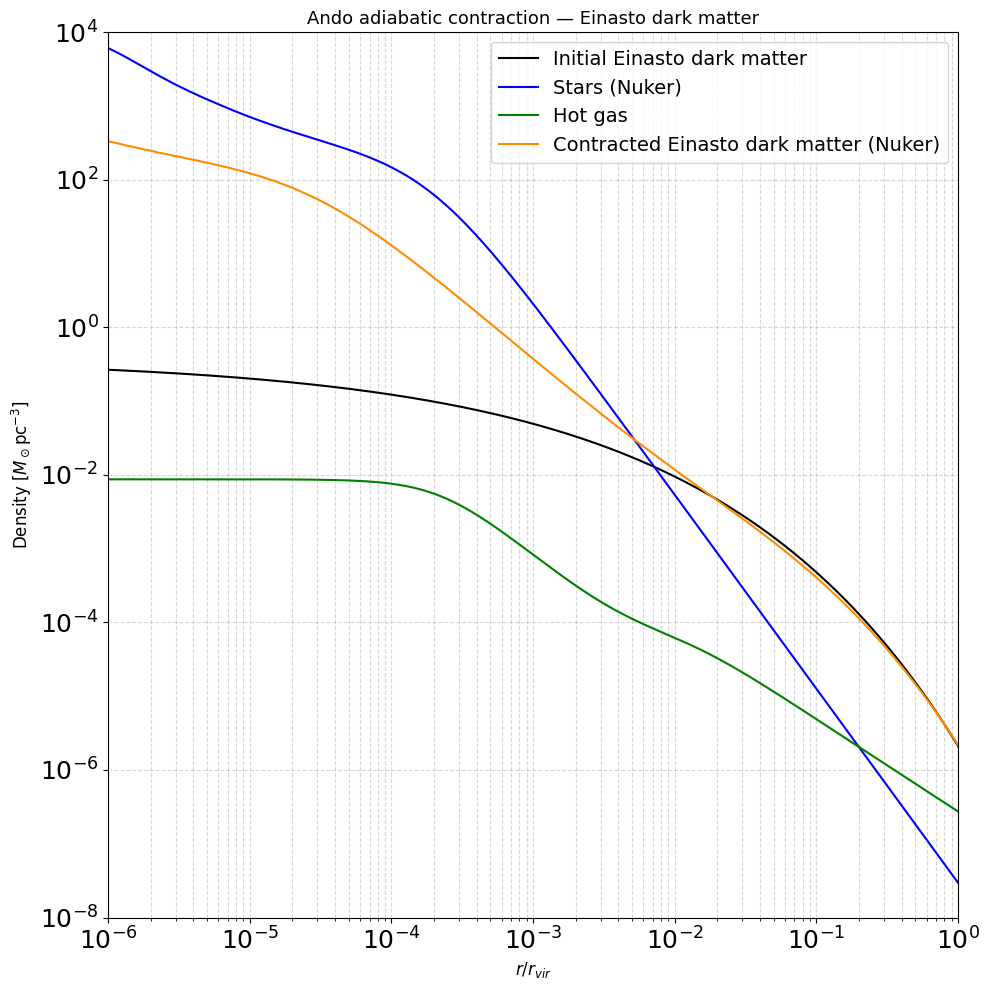

In [8]:
plt.figure(figsize=(fig,fig))
plt.loglog(r_norm, rho_dm / factor, label=f'Initial {config.DM_PROFILE.capitalize()} dark matter', color = 'black')
plt.loglog(r_norm, rho_b / factor, label=f'Stars ({config.BARYON_PROFILE.capitalize()})', color ='blue')
plt.loglog(r_norm, rho_gaz / factor, label='Hot gas', color='green')
plt.loglog(rf_contracted / halo.r_vir, rho_contracted / factor, label=f'Contracted {config.DM_PROFILE.capitalize()} dark matter ({config.BARYON_PROFILE.capitalize()})', color ='darkorange')

plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max) 
plt.xlabel(r'$r/r_{vir}$', fontsize=12)
plt.ylabel(r'Density [$M_\odot \mathrm{pc}^{-3}$]', fontsize=12)
plt.title(f'{config.CONTRACTION.capitalize()} adiabatic contraction — {config.DM_PROFILE.capitalize()} dark matter', fontsize=13)
plt.grid(True, which='both', ls='--', alpha=0.5)
plt.legend(fontsize=14, loc='upper right')
plt.tight_layout()
plt.show()

Import the data from Shin’ichiro Ando and Daisuke Nagai (2012) to compare them with my data

In [9]:
hot_gas = '../Data/Data_Ando/Hot_gas.csv'
df_hot_gas = pd.read_csv(hot_gas, sep=';', decimal=',', header=None)

stars = '../Data/Data_Ando/Stars.csv'
df_stars = pd.read_csv(stars, sep=';', decimal=',', header=None)

nfw = '../Data/Data_Ando/NFW.csv'
df_nfw = pd.read_csv(nfw, sep=';', decimal=',', header=None)

einasto = '../Data/Data_Ando/Einasto.csv'
df_einasto = pd.read_csv(einasto, sep=';', decimal=',', header=None)

contraction_nfw = '../Data/Data_Ando/Contraction_NFW.csv'
df_contraction_nfw = pd.read_csv(contraction_nfw, sep=';', decimal=',', header=None)

contraction_einasto = '../Data/Data_Ando/Contraction_Einasto.csv'
df_contraction_einasto = pd.read_csv(contraction_einasto, sep=';', decimal=',', header=None)

Plot of the data from Shin’ichiro Ando and Daisuke Nagai (2012)

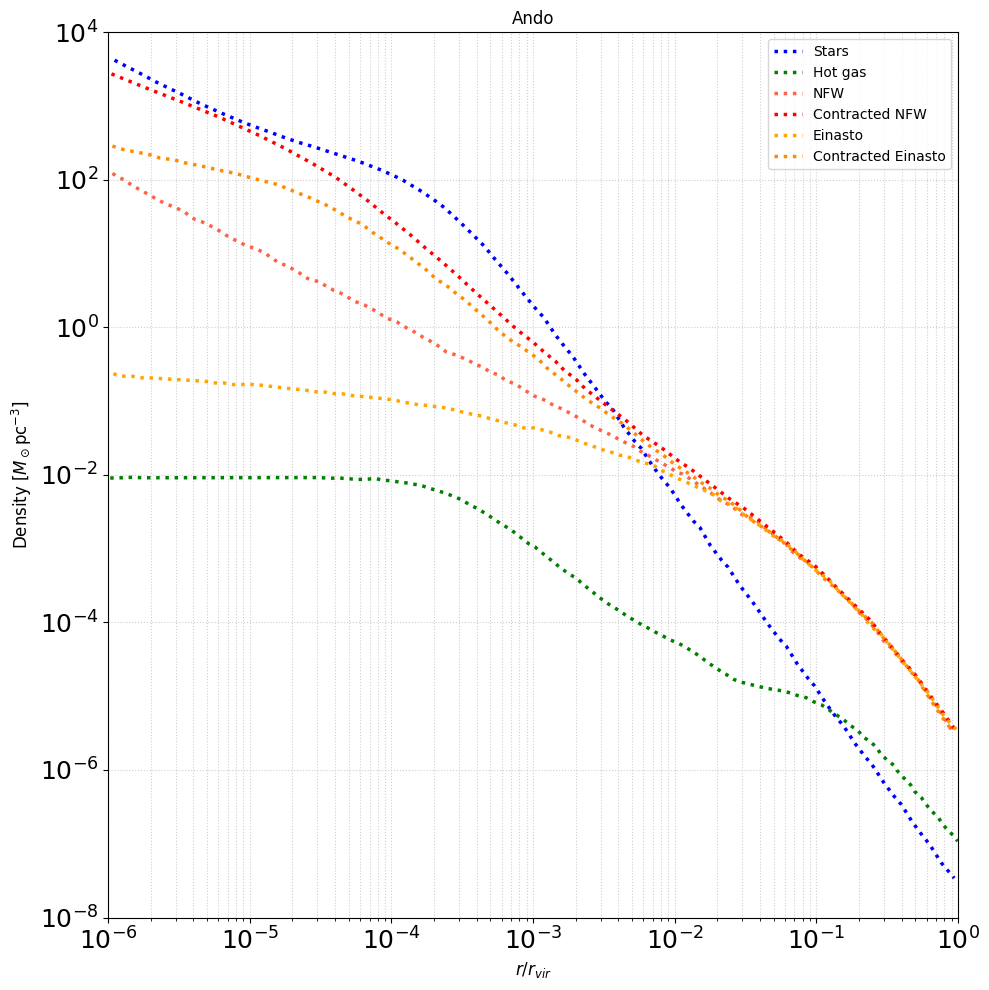

In [10]:
plt.figure(figsize=(fig,fig))
plt.loglog(df_stars[0], df_stars[1], label='Stars', ls=':', lw=2.5, color='blue')
plt.loglog(df_hot_gas[0], df_hot_gas[1], label='Hot gas', ls=':', lw=2.5, color='green')
plt.loglog(df_nfw[0], df_nfw[1], label='NFW', ls=':', lw=2.5, color='tomato')
plt.loglog(df_contraction_nfw[0], df_contraction_nfw[1], label='Contracted NFW', ls=':', lw=2.5, color='red')
plt.loglog(df_einasto[0], df_einasto[1], label='Einasto', ls=':', lw=2.5, color='orange')
plt.loglog(df_contraction_einasto[0], df_contraction_einasto[1], label='Contracted Einasto', ls=':', lw=2.5, color='darkorange')
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.title('Ando')
plt.xlabel(r'$r/r_{vir}$', fontsize=12)
plt.ylabel(r'Density [$M_\odot \mathrm{pc}^{-3}$]', fontsize=12)
plt.legend() 
plt.grid(True, which="both", ls=":", alpha=0.6)
plt.tight_layout()

plt.show()

Comparison of the data

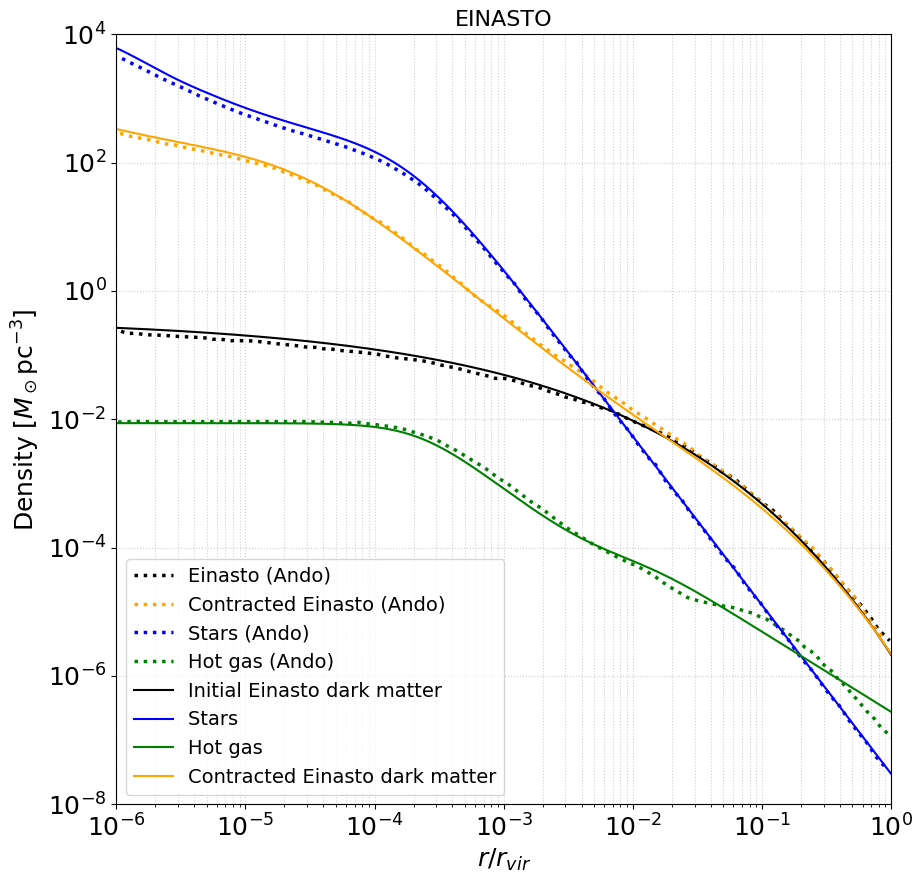

In [11]:
plt.figure(figsize=(fig,fig))

if config.DM_PROFILE == 'NFW':
    plt.loglog(df_nfw[0], df_nfw[1], label='NFW (Ando)', ls=':', lw=2.5, color='black')
    plt.loglog(df_contraction_nfw[0], df_contraction_nfw[1], label='Contracted NFW (Ando)', ls=':', lw=2.5, color='orange')
    title_dm = 'NFW'

elif config.DM_PROFILE == 'Einasto':
    plt.loglog(df_einasto[0], df_einasto[1], label='Einasto (Ando)', ls=':', lw=2.5, color='black')
    plt.loglog(df_contraction_einasto[0], df_contraction_einasto[1], label='Contracted Einasto (Ando)', ls=':', lw=2.5, color='orange')
    title_dm = 'Einasto'

plt.loglog(df_stars[0], df_stars[1], label='Stars (Ando)', ls=':', lw=2.5, color='blue')
plt.loglog(df_hot_gas[0], df_hot_gas[1], label='Hot gas (Ando)', ls=':', lw=2.5, color='green')

plt.loglog(r_norm, rho_dm / factor, label=f'Initial {config.DM_PROFILE.capitalize()} dark matter', color = 'black')
plt.loglog(r_norm, rho_b / factor, label=f'Stars ', color ='blue')
plt.loglog(r_norm, rho_gaz / factor, label='Hot gas', color='green', linestyle='-')
plt.loglog(rf_contracted / halo.r_vir, rho_contracted / factor, label=f'Contracted {config.DM_PROFILE.capitalize()} dark matter', color ='orange')


plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.xlabel(r'$r/r_{vir}$', fontsize=18) 
plt.ylabel(r'Density [$M_\odot \mathrm{pc}^{-3}$]', fontsize=18)
plt.title(f'{config.DM_PROFILE.upper()}', fontsize=16)
plt.grid(True, which="both", ls=":", alpha=0.6)
plt.legend(loc = 'lower left', fontsize=14)
plt.show()